# Synthetic Work-From-Home Burnout Analysis and Modelling

## Dataset Loading and Initial Inspection

This notebook presents a supplementary analysis using a synthetic work-from-home burnout dataset. The synthetic dataset does not replace the independently analysed real-world datasets and is not treated as empirical evidence about real workers.

Instead, it is used to examine the application of the common analytical framework to a cleanly structured dataset containing work-pattern, behavioural and burnout-related variables.

The dataset is analysed independently using the same general framework applied to the real-world datasets, including outcome assessment, predictor mapping, preprocessing, exploratory analysis, interpretable machine-learning modelling, performance evaluation and model interpretation.

In [1]:
import pandas as pd
import numpy as np

# Load the synthetic work-from-home burnout dataset
wfh = pd.read_csv('/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Burnout Datasets (Raw)/work_from_home_burnout_dataset.csv')

print("Dataset shape:", wfh.shape)

print("\nColumns:")
print(wfh.columns.tolist())

print("\nFirst five rows:")
display(wfh.head())

Dataset shape: (1800, 11)

Columns:
['user_id', 'day_type', 'work_hours', 'screen_time_hours', 'meetings_count', 'breaks_taken', 'after_hours_work', 'sleep_hours', 'task_completion_rate', 'burnout_score', 'burnout_risk']

First five rows:


,user_id,day_type,work_hours,screen_time_hours,meetings_count,breaks_taken,after_hours_work,sleep_hours,task_completion_rate,burnout_score,burnout_risk
0,1,Weekday,9.59,11.86,4,2,0,7.55,91.2,19.17,Low
1,1,Weekend,7.38,10.33,4,1,0,6.69,82.0,29.70,Low
2,1,Weekend,6.31,8.92,1,2,0,8.87,80.6,32.93,Low
3,1,Weekday,8.34,10.70,4,1,1,8.13,70.0,45.47,Low
4,1,Weekend,6.97,9.83,1,2,0,5.85,67.1,51.61,Low


## Dataset Structure and Data Quality

The structure and quality of the synthetic dataset were assessed before outcome construction and predictor selection. This included examination of data types, missing values, duplicate observations, the number of unique users and the number of daily observations recorded per user.

Because the dataset contains repeated daily observations for individual users, the user-level structure was also examined to inform the later training and test split and reduce the risk of information leakage between observations belonging to the same individual.

In [2]:
# Inspect dataset structure and data quality

print("Dataset dimensions:")
print(f"Rows: {wfh.shape[0]}")
print(f"Columns: {wfh.shape[1]}")

print("\nData types:")
print(wfh.dtypes)

print("\nTotal missing values:")
print(wfh.isnull().sum().sum())

print("\nDuplicate rows:")
print(wfh.duplicated().sum())

print("\nUnique users:")
print(wfh["user_id"].nunique())

print("\nObservations per user:")
print(wfh.groupby("user_id").size().describe())

print("\nUnique values per column:")
print(wfh.nunique())

Dataset dimensions:
Rows: 1800
Columns: 11

Data types:
user_id                   int64
day_type                 object
work_hours              float64
screen_time_hours       float64
meetings_count            int64
breaks_taken              int64
after_hours_work          int64
sleep_hours             float64
task_completion_rate    float64
burnout_score           float64
burnout_risk             object
dtype: object

Total missing values:
0

Duplicate rows:
0

Unique users:
180

Observations per user:
count    180.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
dtype: float64

Unique values per column:
user_id                  180
day_type                   2
work_hours               689
screen_time_hours        785
meetings_count            11
breaks_taken               5
after_hours_work           2
sleep_hours              452
task_completion_rate     520
burnout_score           1603
burnout_risk               3
dtype: int

## Burnout Outcome Verification

The dataset contains both a continuous `burnout_score` and a categorical `burnout_risk` classification. Their relationship was examined before selecting the modelling outcome.

This assessment was conducted to determine how the supplied risk categories relate to the continuous burnout score and to prevent the direct burnout score from being included as a predictor if it determines the risk classification.

In [3]:
# Examine the relationship between burnout score and supplied risk category

print("Burnout-risk distribution:")
print(wfh["burnout_risk"].value_counts())

print("\nBurnout-risk percentages:")
print(
    wfh["burnout_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("\nBurnout score by risk category:")
display(
    wfh.groupby("burnout_risk")["burnout_score"]
    .agg(["count", "min", "max", "mean", "median"])
    .round(2)
)

print("\nOverall burnout-score summary:")
display(
    wfh["burnout_score"]
    .describe()
    .round(2)
)

Burnout-risk distribution:
burnout_risk
Low       1527
Medium     253
High        20
Name: count, dtype: int64

Burnout-risk percentages:
burnout_risk
Low       84.8
Medium    14.1
High       1.1
Name: proportion, dtype: float64

Burnout score by risk category:


,count,min,max,mean,median
burnout_risk,,,,,
High,20,110.22,143.92,122.57,121.38
Low,1527,2.50,69.92,36.34,34.72
Medium,253,70.01,109.99,84.09,82.19



Overall burnout-score summary:


count    1800.00
mean       44.01
std        23.88
min         2.50
25%        25.37
50%        39.27
75%        58.20
max       143.92
Name: burnout_score, dtype: float64

**Outcome decision:**  
The supplied burnout-risk classification was directly associated with the continuous burnout score. Low-risk observations had burnout scores between 2.50 and 69.92, Medium-risk observations ranged from 70.01 to 109.99, and High-risk observations ranged from 110.22 to 143.92.

The High-risk category contained only 20 observations (1.1%), making separate three-class modelling unsuitable for the present analysis. To maintain the study's binary early-risk classification framework while preserving the supplied risk structure, Medium and High categories were combined into an elevated-risk class. Low-risk observations were retained as the lower-risk class.

The continuous `burnout_score` was excluded from the predictor set because it directly determines the supplied risk classification and would introduce target leakage.

In [4]:
# Create binary burnout-risk outcome
# 0 = Lower risk (Low)
# 1 = Elevated risk (Medium or High)

wfh["Burnout_Risk_Binary"] = (
    wfh["burnout_risk"].isin(["Medium", "High"])
).astype(int)

print("Binary burnout-risk counts:")
print(wfh["Burnout_Risk_Binary"].value_counts().sort_index())

print("\nBinary burnout-risk percentages:")
print(
    wfh["Burnout_Risk_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(1)
)

Binary burnout-risk counts:
Burnout_Risk_Binary
0    1527
1     273
Name: count, dtype: int64

Binary burnout-risk percentages:
Burnout_Risk_Binary
0    84.8
1    15.2
Name: proportion, dtype: float64


## LLM-Assisted Predictor Mapping and Researcher Validation

The dataset was already presented in English; therefore, language translation was not required. Variable names, observed values and conceptual meanings were reviewed before modelling.

Consistent with the common analytical framework, LLM-assisted semantic mapping was used to organise variables into conceptual groups and propose their analytical roles. The proposed mappings were subsequently reviewed and validated by the researcher.

`user_id` was treated as a grouping identifier rather than a predictor because multiple daily observations were recorded for each user. The supplied `burnout_score` and original `burnout_risk` classification were excluded from the predictor set because they directly determine the binary modelling outcome.


In [5]:
# Create predictor mapping and audit table

predictor_audit = pd.DataFrame([
    ["user_id",
     "Identifier",
     "Exclude from predictors",
     "Identifies repeated observations belonging to the same user"],

    ["day_type",
     "Work pattern",
     "Candidate predictor",
     "Distinguishes weekday and weekend observations"],

    ["work_hours",
     "Work demands",
     "Candidate predictor",
     "Daily working hours"],

    ["screen_time_hours",
     "Work demands",
     "Candidate predictor",
     "Daily screen-time duration"],

    ["meetings_count",
     "Work demands",
     "Candidate predictor",
     "Number of meetings"],

    ["breaks_taken",
     "Work behaviour",
     "Candidate predictor",
     "Number of breaks taken"],

    ["after_hours_work",
     "Work demands",
     "Candidate predictor",
     "Indicates whether work occurred after normal working hours"],

    ["sleep_hours",
     "Wellbeing",
     "Candidate predictor",
     "Daily sleep duration"],

    ["task_completion_rate",
     "Work performance",
     "Candidate predictor",
     "Task-completion performance measure"],

    ["burnout_score",
     "Burnout outcome",
     "Exclude",
     "Continuous score directly determining the supplied burnout-risk classification"],

    ["burnout_risk",
     "Burnout outcome",
     "Exclude",
     "Original three-category outcome used to construct the binary target"],

    ["Burnout_Risk_Binary",
     "Burnout outcome",
     "Outcome",
     "Binary outcome: Low = 0 and Medium/High = 1"]
], columns=[
    "Variable",
    "Conceptual_Group",
    "Proposed_Role",
    "Reason"
])

display(predictor_audit)

,Variable,Conceptual_Group,Proposed_Role,Reason
0,user_id,Identifier,Exclude from predictors,Identifies repeated observations belonging to ...
1,day_type,Work pattern,Candidate predictor,Distinguishes weekday and weekend observations
2,work_hours,Work demands,Candidate predictor,Daily working hours
3,screen_time_hours,Work demands,Candidate predictor,Daily screen-time duration
4,meetings_count,Work demands,Candidate predictor,Number of meetings
5,breaks_taken,Work behaviour,Candidate predictor,Number of breaks taken
6,after_hours_work,Work demands,Candidate predictor,Indicates whether work occurred after normal w...
7,sleep_hours,Wellbeing,Candidate predictor,Daily sleep duration
8,task_completion_rate,Work performance,Candidate predictor,Task-completion performance measure
9,burnout_score,Burnout outcome,Exclude,Continuous score directly determining the supp...


In [6]:
# Record researcher validation of the proposed mappings

predictor_audit["Researcher_Validated"] = "Yes"
predictor_audit["Final_Role"] = predictor_audit["Proposed_Role"]

display(predictor_audit)

,Variable,Conceptual_Group,Proposed_Role,Reason,Researcher_Validated,Final_Role
0,user_id,Identifier,Exclude from predictors,Identifies repeated observations belonging to ...,Yes,Exclude from predictors
1,day_type,Work pattern,Candidate predictor,Distinguishes weekday and weekend observations,Yes,Candidate predictor
2,work_hours,Work demands,Candidate predictor,Daily working hours,Yes,Candidate predictor
3,screen_time_hours,Work demands,Candidate predictor,Daily screen-time duration,Yes,Candidate predictor
4,meetings_count,Work demands,Candidate predictor,Number of meetings,Yes,Candidate predictor
5,breaks_taken,Work behaviour,Candidate predictor,Number of breaks taken,Yes,Candidate predictor
6,after_hours_work,Work demands,Candidate predictor,Indicates whether work occurred after normal w...,Yes,Candidate predictor
7,sleep_hours,Wellbeing,Candidate predictor,Daily sleep duration,Yes,Candidate predictor
8,task_completion_rate,Work performance,Candidate predictor,Task-completion performance measure,Yes,Candidate predictor
9,burnout_score,Burnout outcome,Exclude,Continuous score directly determining the supp...,Yes,Exclude


## Pre-Modelling Exploratory Data Analysis

Exploratory analysis was conducted before model development to examine the candidate predictors and their relationships with the binary burnout-risk outcome.

Because the dataset contains repeated daily observations for individual users, the descriptive findings represent observation-level patterns rather than independent participant-level estimates. These relationships are exploratory and should not be interpreted as causal effects.

In [7]:
# Compare numerical predictors between burnout-risk groups

numerical_predictors = [
    "work_hours",
    "screen_time_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate"
]

risk_summary = (
    wfh
    .groupby("Burnout_Risk_Binary")[numerical_predictors]
    .mean()
    .T
)

risk_summary.columns = [
    "Lower Risk Mean",
    "Elevated Risk Mean"
]

risk_summary["Difference"] = (
    risk_summary["Elevated Risk Mean"]
    - risk_summary["Lower Risk Mean"]
)

display(risk_summary.round(2))

,Lower Risk Mean,Elevated Risk Mean,Difference
work_hours,6.46,6.80,0.33
screen_time_hours,9.22,9.59,0.37
meetings_count,1.92,2.07,0.16
breaks_taken,3.03,3.03,0.00
after_hours_work,0.36,0.36,-0.00
sleep_hours,7.00,6.99,-0.01
task_completion_rate,76.86,46.88,-29.98


### Correlation Assessment

Correlations among the numerical predictors, burnout score and binary burnout-risk outcome were examined to identify the strength and direction of relationships before model development.

Because the binary risk outcome is numerically coded as 0 and 1, its correlation with continuous predictors provides a descriptive indication of association rather than a causal interpretation.

In [8]:
# Examine correlations among numerical variables and burnout outcomes

correlation_variables = [
    "work_hours",
    "screen_time_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate",
    "burnout_score",
    "Burnout_Risk_Binary"
]

correlation_matrix = (
    wfh[correlation_variables]
    .corr()
)

burnout_correlations = (
    correlation_matrix[
        ["burnout_score", "Burnout_Risk_Binary"]
    ]
    .drop(
        index=["burnout_score", "Burnout_Risk_Binary"]
    )
    .sort_values(
        "Burnout_Risk_Binary",
        key=abs,
        ascending=False
    )
)

display(burnout_correlations.round(3))

,burnout_score,Burnout_Risk_Binary
task_completion_rate,-0.960,-0.718
screen_time_hours,0.123,0.055
work_hours,0.119,0.052
meetings_count,0.085,0.033
after_hours_work,0.018,-0.003
sleep_hours,-0.006,-0.002
breaks_taken,0.004,0.001


In [9]:
import plotly.express as px

# Correlation heatmap for numerical variables

heatmap_variables = [
    "work_hours",
    "screen_time_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate",
    "burnout_score"
]

heatmap_corr = wfh[heatmap_variables].corr()

fig = px.imshow(
    heatmap_corr,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Correlation Matrix of Synthetic Work-From-Home Variables"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=650
)

fig.show()

**Interpretation:**  
Task completion rate showed a very strong negative relationship with burnout score (r = -0.96), indicating that higher burnout scores were associated with substantially lower task completion within the synthetic dataset. Work hours and screen time were also strongly positively correlated (r = 0.95), indicating potential multicollinearity that requires consideration before Logistic Regression modelling.

Other predictors showed substantially weaker relationships with burnout score. As the dataset is synthetic, these relationships reflect the structure of the generated data and should not be interpreted as empirical evidence about real-world workers.

In [10]:
# Create readable burnout-risk labels

wfh["Risk_Group"] = wfh["Burnout_Risk_Binary"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

fig = px.violin(
    wfh,
    x="Risk_Group",
    y="task_completion_rate",
    box=True,
    points="all",
    category_orders={
        "Risk_Group": ["Lower Risk", "Elevated Risk"]
    },
    labels={
        "Risk_Group": "Burnout-Risk Group",
        "task_completion_rate": "Task Completion Rate"
    },
    title="Task Completion Rate by Burnout-Risk Group"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=560
)

fig.show()

In [11]:
# Examine burnout risk by day type

day_type_summary = (
    wfh.groupby("day_type")["Burnout_Risk_Binary"]
    .agg(["count", "sum"])
    .rename(columns={
        "count": "Observations",
        "sum": "Elevated_Risk"
    })
)

day_type_summary["Elevated_Risk_Rate"] = (
    day_type_summary["Elevated_Risk"]
    / day_type_summary["Observations"]
    * 100
).round(1)

display(day_type_summary)

,Observations,Elevated_Risk,Elevated_Risk_Rate
day_type,,,
Weekday,876,152,17.4
Weekend,924,121,13.1


## Final Predictor Assessment and Multicollinearity

Before constructing the final modelling dataset, multicollinearity among the numerical candidate predictors was assessed.

Exploratory analysis identified a particularly strong correlation between work hours and screen time. Variance Inflation Factors (VIFs) were therefore examined to determine whether highly correlated predictors required adjustment before Logistic Regression modelling.

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Numerical predictors considered for modelling
vif_variables = [
    "work_hours",
    "screen_time_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate"
]

# Standardise before calculating VIF
vif_scaled = StandardScaler().fit_transform(
    wfh[vif_variables]
)

vif_results = pd.DataFrame({
    "Variable": vif_variables,
    "VIF": [
        variance_inflation_factor(vif_scaled, i)
        for i in range(len(vif_variables))
    ]
})

vif_results = vif_results.sort_values(
    "VIF",
    ascending=False
)

display(vif_results.round(2))

,Variable,VIF
0,work_hours,11.68
1,screen_time_hours,11.26
2,meetings_count,1.37
6,task_completion_rate,1.02
3,breaks_taken,1.00
4,after_hours_work,1.00
5,sleep_hours,1.00


**Multicollinearity assessment:**  
Work hours and screen time showed substantial multicollinearity, with VIF values of 11.68 and 11.26 respectively, consistent with their strong correlation (r = 0.95). The remaining numerical predictors showed low VIF values.

To reduce redundant information and improve the interpretability of the Logistic Regression model, `work_hours` was retained as the primary work-duration measure and `screen_time_hours` was excluded from the final predictor set.

In [13]:
# Define final predictor set and modelling outcome

final_predictors = [
    "day_type",
    "work_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate"
]

X = wfh[final_predictors].copy()
y = wfh["Burnout_Risk_Binary"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFinal predictors:")
for predictor in final_predictors:
    print(f"- {predictor}")

print("\nTarget distribution:")
print(y.value_counts().sort_index())

X shape: (1800, 7)
y shape: (1800,)

Final predictors:
- day_type
- work_hours
- meetings_count
- breaks_taken
- after_hours_work
- sleep_hours
- task_completion_rate

Target distribution:
Burnout_Risk_Binary
0    1527
1     273
Name: count, dtype: int64


## User-Level Train/Test Split

Because the dataset contains repeated daily observations for each user, the training and test sets were separated at the user level rather than randomly splitting individual observations.

This ensured that all observations belonging to a particular user appeared exclusively in either the training or held-out test set. The approach reduces information leakage between repeated observations and provides a more rigorous assessment of model performance on previously unseen users.

In [14]:
from sklearn.model_selection import GroupShuffleSplit

# Split entire users between training and test sets
groups = wfh["user_id"]

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_users = set(groups.iloc[train_idx])
test_users = set(groups.iloc[test_idx])

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining users:", len(train_users))
print("Test users:", len(test_users))

print("\nUsers appearing in both sets:")
print(len(train_users.intersection(test_users)))

print("\nTraining target:")
print(y_train.value_counts().sort_index())

print("\nTest target:")
print(y_test.value_counts().sort_index())

print("\nElevated-risk percentage:")
print(f"Training: {y_train.mean() * 100:.1f}%")
print(f"Test: {y_test.mean() * 100:.1f}%")

Training set: (1440, 7)
Test set: (360, 7)

Training users: 144
Test users: 36

Users appearing in both sets:
0

Training target:
Burnout_Risk_Binary
0    1233
1     207
Name: count, dtype: int64

Test target:
Burnout_Risk_Binary
0    294
1     66
Name: count, dtype: int64

Elevated-risk percentage:
Training: 14.4%
Test: 18.3%


## Modelling Preprocessing Pipeline

A preprocessing pipeline was constructed using only the training data. Numerical predictors were standardised for Logistic Regression, while the categorical `day_type` variable was one-hot encoded.

The same fitted preprocessing transformations were subsequently applied to the held-out test data. The test set remained untouched during model development and hyperparameter optimisation.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Define feature types
numerical_features = [
    "work_hours",
    "meetings_count",
    "breaks_taken",
    "after_hours_work",
    "sleep_hours",
    "task_completion_rate"
]

categorical_features = [
    "day_type"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Preprocessing for Logistic Regression
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Preprocessing for Decision Tree
dt_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("\nPreprocessing pipelines created successfully.")

Numerical features: ['work_hours', 'meetings_count', 'breaks_taken', 'after_hours_work', 'sleep_hours', 'task_completion_rate']
Categorical features: ['day_type']

Preprocessing pipelines created successfully.


## Baseline Model Development and Cross-Validation

Baseline Logistic Regression and Decision Tree classifiers were developed using the training data.

Because multiple daily observations were recorded for each user, five-fold group-aware cross-validation was used. This ensured that observations belonging to the same user remained within the same cross-validation fold while approximately preserving the burnout-risk class distribution.

Model performance was evaluated using accuracy, precision, recall, F1-score and ROC-AUC. Particular attention was given to recall, F1-score and ROC-AUC because the elevated-risk class represented a smaller proportion of observations.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Create baseline models
baseline_lr = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

baseline_dt = Pipeline([
    ("preprocessor", dt_preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

# User IDs corresponding only to the training observations
train_groups = groups.iloc[train_idx]

# Group-aware 5-fold cross-validation
group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Evaluate Logistic Regression
lr_cv = cross_validate(
    baseline_lr,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring=scoring
)

# Evaluate Decision Tree
dt_cv = cross_validate(
    baseline_dt,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring=scoring
)

# Summarise mean cross-validation performance
baseline_cv_results = pd.DataFrame({
    "Logistic Regression": {
        metric: lr_cv[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Decision Tree": {
        metric: dt_cv[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

print("Baseline Group-Aware 5-Fold Cross-Validation Results:")
display(baseline_cv_results.round(3))

Baseline Group-Aware 5-Fold Cross-Validation Results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.970,0.909,0.870,0.888,0.993
Decision Tree,0.945,0.816,0.798,0.804,0.884


## Hyperparameter Tuning

Hyperparameter tuning was conducted using only the training data and the same five-fold group-aware cross-validation procedure used for baseline evaluation.

F1-score was used as the primary optimisation metric because it balances precision and recall for the minority elevated-risk class. The held-out test users remained completely excluded from the tuning process.

In [17]:
from sklearn.model_selection import GridSearchCV

# Logistic Regression hyperparameter grid
lr_param_grid = {
    "model__C": [0.01, 0.1, 0.5, 1, 5, 10],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"]
}

lr_grid = GridSearchCV(
    estimator=baseline_lr,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=group_cv,
    n_jobs=-1
)

lr_grid.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("\nBest group-aware cross-validation F1:")
print(round(lr_grid.best_score_, 3))

Best Logistic Regression parameters:
{'model__C': 0.5, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

Best group-aware cross-validation F1:
0.892


In [18]:
# Decision Tree hyperparameter grid

dt_param_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 5, 10, 20]
}

dt_grid = GridSearchCV(
    estimator=baseline_dt,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=group_cv,
    n_jobs=-1
)

dt_grid.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("\nBest group-aware cross-validation F1:")
print(round(dt_grid.best_score_, 3))

Best Decision Tree parameters:
{'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}

Best group-aware cross-validation F1:
0.89


### Tuned Cross-Validation Performance

Following hyperparameter optimisation, the tuned Logistic Regression and Decision Tree models were re-evaluated using the same five-fold group-aware cross-validation procedure and the full set of performance metrics.

This enabled direct comparison with the baseline models while maintaining separation between users across validation folds.

In [19]:
# Retrieve the best tuned models

tuned_lr = lr_grid.best_estimator_
tuned_dt = dt_grid.best_estimator_

# Evaluate tuned Logistic Regression
tuned_lr_cv = cross_validate(
    tuned_lr,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring=scoring
)

# Evaluate tuned Decision Tree
tuned_dt_cv = cross_validate(
    tuned_dt,
    X_train,
    y_train,
    groups=train_groups,
    cv=group_cv,
    scoring=scoring
)

# Summarise tuned cross-validation performance
tuned_cv_results = pd.DataFrame({
    "Tuned Logistic Regression": {
        metric: tuned_lr_cv[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Tuned Decision Tree": {
        metric: tuned_dt_cv[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

print("Tuned Group-Aware 5-Fold Cross-Validation Results:")
display(tuned_cv_results.round(3))

Tuned Group-Aware 5-Fold Cross-Validation Results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Tuned Logistic Regression,0.971,0.905,0.880,0.892,0.993
Tuned Decision Tree,0.969,0.892,0.889,0.890,0.988


## Final Held-Out Test Evaluation

Following model development and hyperparameter optimisation, the tuned models were evaluated once on the held-out test set containing observations from 36 users who were not included during training or cross-validation.

This provides the final assessment of predictive performance on previously unseen users. No further model selection or hyperparameter optimisation was conducted using the held-out test results.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Fit tuned models on the complete training set
tuned_lr.fit(X_train, y_train)
tuned_dt.fit(X_train, y_train)

# Generate predictions
lr_pred = tuned_lr.predict(X_test)
dt_pred = tuned_dt.predict(X_test)

lr_prob = tuned_lr.predict_proba(X_test)[:, 1]
dt_prob = tuned_dt.predict_proba(X_test)[:, 1]


def evaluate_model(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


lr_test_results = evaluate_model(
    y_test,
    lr_pred,
    lr_prob
)

dt_test_results = evaluate_model(
    y_test,
    dt_pred,
    dt_prob
)

heldout_results = pd.DataFrame(
    {
        "Tuned Logistic Regression": lr_test_results,
        "Tuned Decision Tree": dt_test_results
    }
).T

print("Held-Out Test Results:")
display(heldout_results.round(3))

Held-Out Test Results:


,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
Tuned Logistic Regression,0.961,0.933,0.848,0.889,0.993,290.0,4.0,10.0,56.0
Tuned Decision Tree,0.956,0.868,0.894,0.881,0.978,285.0,9.0,7.0,59.0


**Interpretation:**  
Both tuned models demonstrated strong predictive performance on observations from previously unseen users. Logistic Regression achieved an accuracy of 0.961, precision of 0.933, recall of 0.848, F1-score of 0.889 and ROC-AUC of 0.993. It correctly identified 56 of the 66 elevated-risk observations in the held-out test set.

The tuned Decision Tree achieved an accuracy of 0.956, precision of 0.868, recall of 0.894, F1-score of 0.881 and ROC-AUC of 0.978. It correctly identified 59 of the 66 elevated-risk observations, resulting in fewer false negatives than Logistic Regression.

Performance was also consistent with the group-aware cross-validation results, suggesting stable predictive performance across unseen users within the synthetic dataset. However, these strong results should be interpreted in the context of the generated data structure, particularly the strong relationship between task completion rate and the burnout outcome. They do not represent expected performance in real-world occupational settings.

In [21]:
import plotly.express as px

# Confusion matrices
lr_cm = confusion_matrix(y_test, lr_pred)
dt_cm = confusion_matrix(y_test, dt_pred)

class_labels = [
    "Lower Risk",
    "Elevated Risk"
]

# Logistic Regression confusion matrix
fig_lr = px.imshow(
    lr_cm,
    text_auto=True,
    x=["Predicted Lower Risk", "Predicted Elevated Risk"],
    y=["Actual Lower Risk", "Actual Elevated Risk"],
    color_continuous_scale="Viridis",
    labels={"color": "Observations"},
    title="Final Logistic Regression – Held-Out Test Confusion Matrix"
)

fig_lr.update_layout(
    template="plotly_white",
    title_x=0.5,
    width=720,
    height=520,
    xaxis_title="Predicted Class",
    yaxis_title="Actual Class"
)

fig_lr.show()


# Decision Tree confusion matrix
fig_dt = px.imshow(
    dt_cm,
    text_auto=True,
    x=["Predicted Lower Risk", "Predicted Elevated Risk"],
    y=["Actual Lower Risk", "Actual Elevated Risk"],
    color_continuous_scale="Viridis",
    labels={"color": "Observations"},
    title="Tuned Decision Tree – Held-Out Test Confusion Matrix"
)

fig_dt.update_layout(
    template="plotly_white",
    title_x=0.5,
    width=720,
    height=520,
    xaxis_title="Predicted Class",
    yaxis_title="Actual Class"
)

fig_dt.show()

### Decision Tree Structure

The structure of the tuned Decision Tree was visualised to demonstrate how the interpretable model classified lower- and elevated-risk observations.

Because hyperparameter tuning selected a maximum tree depth of three, the resulting model remained sufficiently compact to allow direct visual inspection of its decision rules.

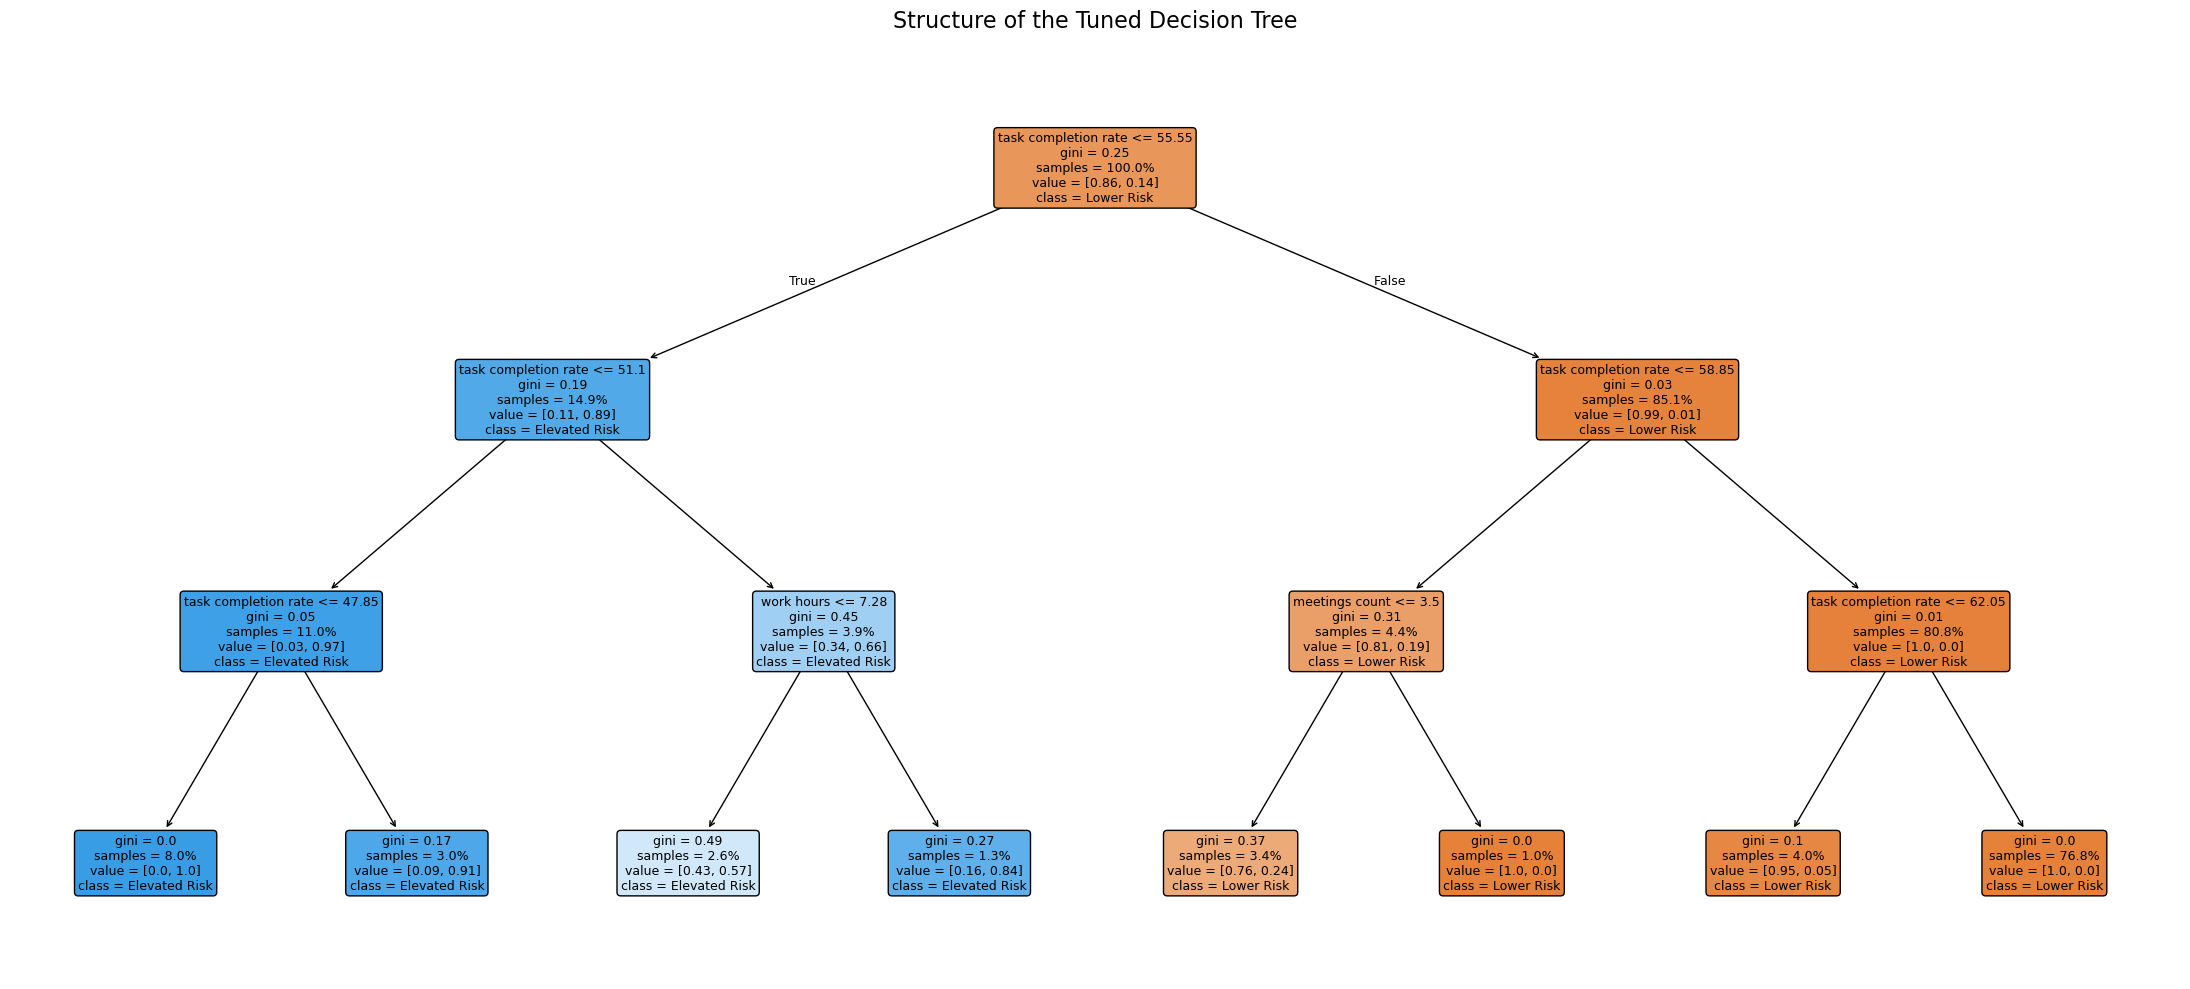

In [22]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract fitted preprocessing and Decision Tree model
dt_preprocessor_fitted = tuned_dt.named_steps["preprocessor"]
dt_model_fitted = tuned_dt.named_steps["model"]

# Retrieve transformed feature names
dt_feature_names = dt_preprocessor_fitted.get_feature_names_out()

# Clean feature names for readability
clean_feature_names = [
    name
    .replace("num__", "")
    .replace("cat__", "")
    .replace("_", " ")
    for name in dt_feature_names
]

# Plot the complete tuned Decision Tree
plt.figure(figsize=(22, 10))

plot_tree(
    dt_model_fitted,
    feature_names=clean_feature_names,
    class_names=["Lower Risk", "Elevated Risk"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    fontsize=9
)

plt.title(
    "Structure of the Tuned Decision Tree",
    fontsize=16,
    pad=18
)

plt.tight_layout()
plt.show()

**Interpretation:**  
The tuned Decision Tree remained compact with a maximum depth of three, allowing its classification process to be directly inspected. Task completion rate formed the root decision rule and appeared repeatedly throughout the tree, demonstrating its dominant role in distinguishing the synthetic lower- and elevated-risk observations.

Work hours and meeting count contributed additional decision rules within particular branches. The split values represent thresholds learned from the synthetic training data and should not be interpreted as clinical or generalisable burnout thresholds.

In [23]:
# Prepare final held-out performance results for visual comparison

performance_plot = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"
    ],
    "Logistic Regression": [
        lr_test_results["Accuracy"],
        lr_test_results["Precision"],
        lr_test_results["Recall"],
        lr_test_results["F1"],
        lr_test_results["ROC_AUC"]
    ],
    "Decision Tree": [
        dt_test_results["Accuracy"],
        dt_test_results["Precision"],
        dt_test_results["Recall"],
        dt_test_results["F1"],
        dt_test_results["ROC_AUC"]
    ]
})

performance_long = performance_plot.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

fig = px.bar(
    performance_long,
    x="Metric",
    y="Score",
    color="Model",
    barmode="group",
    text_auto=".3f",
    title="Final Held-Out Test Performance on Unseen Users"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    yaxis=dict(
        title="Score",
        range=[0, 1.05]
    ),
    xaxis_title="Performance Metric",
    height=560,
    legend_title="Model"
)

fig.update_traces(
    textposition="inside"
)

fig.show()

## Model Interpretation

### Logistic Regression Coefficients and Odds Ratios

The final Logistic Regression model was interpreted using its fitted coefficients and corresponding odds ratios. Positive coefficients indicate an increased modelled likelihood of elevated burnout risk, while negative coefficients indicate a decreased modelled likelihood, holding the other predictors constant.

Because L1 regularisation was selected during hyperparameter tuning, weaker predictors may be reduced to coefficients of zero. The resulting coefficients describe relationships within the synthetic dataset and should not be interpreted as causal or real-world effect estimates.

In [30]:
# Extract fitted Logistic Regression components

lr_preprocessor_fitted = tuned_lr.named_steps["preprocessor"]
lr_model_fitted = tuned_lr.named_steps["model"]

# Get transformed feature names
lr_feature_names = lr_preprocessor_fitted.get_feature_names_out()

# Extract coefficients
lr_coefficients = lr_model_fitted.coef_[0]

# Create interpretation table
lr_interpretation = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_coefficients,
    "Odds_Ratio": np.exp(lr_coefficients)
})

# Clean feature names
lr_interpretation["Feature"] = (
    lr_interpretation["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Sort by absolute coefficient size
lr_interpretation["Absolute_Coefficient"] = (
    lr_interpretation["Coefficient"].abs()
)

lr_interpretation = (
    lr_interpretation
    .sort_values("Absolute_Coefficient", ascending=False)
    .drop(columns="Absolute_Coefficient")
)

display(lr_interpretation.round(3))

,Feature,Coefficient,Odds_Ratio
5,task completion rate,-5.770,0.003
3,after hours work,-0.215,0.807
6,day type Weekday,-0.133,0.875
4,sleep hours,-0.100,0.905
2,breaks taken,0.056,1.058
1,meetings count,-0.023,0.977
0,work hours,0.000,1.000
7,day type Weekend,0.000,1.000


In [31]:
# Keep only predictors retained by L1 regularisation

lr_nonzero = lr_interpretation[
    lr_interpretation["Coefficient"].abs() > 0.001
].copy()

lr_nonzero = lr_nonzero.sort_values(
    "Coefficient",
    ascending=True
)

fig = px.bar(
    lr_nonzero,
    x="Coefficient",
    y="Feature",
    orientation="h",
    text="Coefficient",
    title="Predictors Retained by the Final Logistic Regression"
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside"
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=520,
    xaxis_title="Standardised Logistic Regression Coefficient",
    yaxis_title="",
    showlegend=False
)

fig.show()

**Interpretation:**  
Task completion rate was the dominant predictor retained by the regularised Logistic Regression model and showed a strong negative association with elevated burnout risk. Because numerical predictors were standardised before model fitting, its coefficient and odds ratio relate to a one-standard-deviation increase rather than a one-unit increase in the original measurement scale.

The remaining retained predictors had substantially smaller coefficients, while work hours was reduced to zero by L1 regularisation. These model coefficients describe the structure of the synthetic dataset and should not be interpreted as causal or generalisable real-world effects.

### Decision Tree Feature Importance

Feature importance values from the tuned Decision Tree were examined to identify which predictors contributed most strongly to its classification decisions.

These values represent the relative contribution of each predictor to reducing classification impurity within the fitted tree. They indicate importance within this synthetic model but do not represent causal effects.

In [32]:
# Extract feature importance from the fitted Decision Tree

dt_importance = pd.DataFrame({
    "Feature": dt_feature_names,
    "Importance": dt_model_fitted.feature_importances_
})

# Clean feature names
dt_importance["Feature"] = (
    dt_importance["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Keep only features actually used by the tree
dt_importance_nonzero = (
    dt_importance[
        dt_importance["Importance"] > 0
    ]
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Decision Tree features with non-zero importance:")
display(dt_importance_nonzero.round(3))

Decision Tree features with non-zero importance:


,Feature,Importance
0,task completion rate,0.989
1,work hours,0.006
2,meetings count,0.004


In [33]:
fig = px.bar(
    dt_importance_nonzero.sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    text="Importance",
    title="Feature Importance in the Tuned Decision Tree"
)

fig.update_traces(
    texttemplate="%{text:.3f}",
    textposition="outside"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=450,
    xaxis_title="Relative Feature Importance",
    yaxis_title="",
    xaxis=dict(range=[0, 1.08]),
    showlegend=False
)

fig.show()

**Interpretation:**  
Task completion rate accounted for 98.9% of the total feature importance in the tuned Decision Tree, confirming that the model relied overwhelmingly on this predictor when classifying burnout risk. Work hours and meeting count contributed only marginally to the tree's decisions.

This finding is consistent with the exploratory analysis, which identified a strong relationship between task completion rate and the synthetic burnout outcome. The dominance of a single predictor also highlights the deliberately structured nature of the synthetic dataset and should not be interpreted as evidence that task completion has equivalent predictive importance in real-world occupational settings.

## Overall Model Performance and Dataset Summary

Model performance was compared across baseline group-aware cross-validation, tuned group-aware cross-validation and final held-out testing on previously unseen users.

This comparison provides an overview of the effect of hyperparameter optimisation and the consistency of model performance between cross-validation and final evaluation.

In [34]:
# Combine baseline, tuned and final model performance

final_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Evaluation Stage": "Baseline Group-Aware CV",
        **baseline_cv_results.loc["Logistic Regression"].to_dict()
    },
    {
        "Model": "Logistic Regression",
        "Evaluation Stage": "Tuned Group-Aware CV",
        **tuned_cv_results.loc["Tuned Logistic Regression"].to_dict()
    },
    {
        "Model": "Logistic Regression",
        "Evaluation Stage": "Final Held-Out Test",
        "Accuracy": lr_test_results["Accuracy"],
        "Precision": lr_test_results["Precision"],
        "Recall": lr_test_results["Recall"],
        "F1": lr_test_results["F1"],
        "ROC_AUC": lr_test_results["ROC_AUC"]
    },
    {
        "Model": "Decision Tree",
        "Evaluation Stage": "Baseline Group-Aware CV",
        **baseline_cv_results.loc["Decision Tree"].to_dict()
    },
    {
        "Model": "Decision Tree",
        "Evaluation Stage": "Tuned Group-Aware CV",
        **tuned_cv_results.loc["Tuned Decision Tree"].to_dict()
    },
    {
        "Model": "Decision Tree",
        "Evaluation Stage": "Final Held-Out Test",
        "Accuracy": dt_test_results["Accuracy"],
        "Precision": dt_test_results["Precision"],
        "Recall": dt_test_results["Recall"],
        "F1": dt_test_results["F1"],
        "ROC_AUC": dt_test_results["ROC_AUC"]
    }
])

final_comparison = final_comparison.rename(
    columns={"ROC_AUC": "ROC-AUC"}
)

final_comparison = final_comparison[
    [
        "Model",
        "Evaluation Stage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

# Display polished comparison table
styled_comparison = (
    final_comparison.style
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
    .background_gradient(
        subset=[
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC"
        ],
        cmap="Blues"
    )
    .set_caption(
        "Overall Model Performance Across Evaluation Stages"
    )
    .set_properties(
        **{
            "text-align": "center",
            "padding": "8px"
        }
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold")
            ]
        }
    ])
    .hide(axis="index")
)

display(styled_comparison)

Model,Evaluation Stage,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,Baseline Group-Aware CV,0.970,0.909,0.870,0.888,0.993
Logistic Regression,Tuned Group-Aware CV,0.971,0.905,0.880,0.892,0.993
Logistic Regression,Final Held-Out Test,0.961,0.933,0.848,0.889,0.993
Decision Tree,Baseline Group-Aware CV,0.945,0.816,0.798,0.804,0.884
Decision Tree,Tuned Group-Aware CV,0.969,0.892,0.889,0.890,0.988
Decision Tree,Final Held-Out Test,0.956,0.868,0.894,0.881,0.978


## Dataset Analysis Summary

The supplementary synthetic work-from-home dataset contained 1,800 daily observations from 180 users, with ten observations recorded for each user. The dataset contained no missing values or duplicate observations. Because repeated measurements were available for individual users, model development and evaluation were conducted using group-aware procedures to prevent observations belonging to the same user from appearing across training, validation and held-out test groups.

The supplied three-category burnout-risk outcome was converted into the study's binary early-risk framework, with Low classified as lower risk and Medium or High classified as elevated risk. This produced 1,527 lower-risk observations (84.8%) and 273 elevated-risk observations (15.2%). The continuous burnout score was excluded from the predictor set because it directly determined the supplied risk classification and would therefore introduce target leakage.

Exploratory analysis identified task completion rate as the dominant burnout-related variable. It showed a strong negative relationship with the continuous burnout score (r = -0.96) and with the binary burnout-risk outcome (r = -0.72). Work hours and screen time were also strongly correlated with one another (r = 0.95). Their VIF values exceeded 11, indicating substantial multicollinearity. Screen time was therefore excluded from the primary modelling predictor set, while work hours was retained as the more directly interpretable occupational-demand measure.

Following predictor assessment, seven variables were retained for modelling: day type, work hours, meeting count, breaks taken, after-hours work, sleep hours and task completion rate. The data were separated at the user level into 144 training users and 36 held-out test users, with no user appearing in both sets.

Both interpretable machine-learning models demonstrated strong performance. On the held-out observations from previously unseen users, Logistic Regression achieved an accuracy of 0.961, precision of 0.933, recall of 0.848, F1-score of 0.889 and ROC-AUC of 0.993. It correctly identified 56 of 66 elevated-risk observations. The tuned Decision Tree achieved an accuracy of 0.956, precision of 0.868, recall of 0.894, F1-score of 0.881 and ROC-AUC of 0.978, correctly identifying 59 of 66 elevated-risk observations.

The two models therefore demonstrated different performance characteristics. Logistic Regression produced higher precision, F1-score and ROC-AUC, whereas the Decision Tree produced higher recall and fewer false negatives. Model interpretation showed that task completion rate dominated both modelling approaches. It had the largest absolute Logistic Regression coefficient and accounted for approximately 98.9% of the Decision Tree's total feature importance. The tuned Decision Tree remained compact at a maximum depth of three, allowing its classification rules to be directly inspected.

Overall, the synthetic analysis demonstrates the behaviour of the common modelling framework when a dataset contains a strong and clearly structured relationship between predictors and the burnout-related outcome. The strong predictive performance contrasts with the more variable performance observed across the independently analysed real-world secondary datasets. However, the synthetic results are supplementary methodological evidence only. They do not constitute empirical evidence about real workers, should not be used to increase the effective sample size of the real-world analyses, and should not be interpreted as demonstrating equivalent predictive performance in real occupational settings.

### Statistical Inference Note

Inferential p-values and confidence intervals were not calculated for the synthetic dataset. Unlike the real-world secondary datasets, these observations were artificially generated and were included as a supplementary methodological analysis rather than as empirical evidence about a real working population.

Consequently, population-level statistical inference from this dataset would not provide meaningful evidence regarding real-world occupational burnout relationships. Interpretation therefore focused on predictive performance, Logistic Regression coefficients and odds ratios, Decision Tree feature importance, and model structure.

The synthetic analysis was used to assess the behaviour and reproducibility of the modelling framework under a larger controlled dataset and was not used to strengthen statistical significance or compensate for the sample sizes of the real-world datasets.